# Scandola — reproducible Tuta absoluta × TOMGRO workflow

This notebook contains the complete workflow used for the Scandola analysis: data preparation, PyCrop imports, simulation-engine construction and bindings, parameter-search blocks, selected simulations, model/observation comparisons, and crop-impact figures.

The notebook is portable: keep it in the same folder as `PyCrop_restrict.zip`, `data/`, and `search_reference/`, then use **Run All**.

In [1]:
from pathlib import Path
import sys, zipfile, contextlib, io, itertools, math, warnings
from decimal import Decimal

import numpy as np

# NumPy 2 renamed trapz -> trapezoid; keep the notebook runnable on both.
_trapz = getattr(np, "trapezoid", None) or np.trapz
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

ROOT = Path.cwd()
DATA = ROOT / "data"
REF = ROOT / "search_reference"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

WORKBOOK = DATA / "scandola_original.xlsx"
CLIMATE_FILE = DATA / "scandola_final_dataset.csv"
PYCROP_ZIP = ROOT / "PyCrop_restrict.zip"

for required in [WORKBOOK, CLIMATE_FILE, PYCROP_ZIP]:
    if not required.exists():
        raise FileNotFoundError(f"Missing required file: {required}")

# Keep False for a fast portable Run All. Set True to rerun search blocks.
RUN_GRID_SEARCHES = False
N_DAYS = 76
START_DATE = pd.Timestamp("2025-05-21")
print("Working directory:", ROOT.name)

Working directory: SCANDOLA_FINAL_REPRODUCIBLE_PACKAGE


## 1. PyCrop import

The source archive is extracted automatically on the first run.

In [2]:
RUNTIME = ROOT / "_pycrop_runtime"
PKG_DIR = RUNTIME / "PyCrop_restrict"
if not PKG_DIR.exists():
    RUNTIME.mkdir(exist_ok=True)
    with zipfile.ZipFile(PYCROP_ZIP) as zf:
        zf.extractall(RUNTIME)

if str(PKG_DIR) not in sys.path:
    sys.path.insert(0, str(PKG_DIR))

from PyCrop.Implementations.Engines.SimulationEngine import SimulationEngine
from PyCrop.Implementations.Inputs.SFMCInputModule import SFMCInputModule
from PyCrop.Abstract.Core.AbstractModule import STEP_GRANULARITY
from PyCrop.Implementations.Environment.SimpleEnvironmentModule import SimpleEnvironmentModule
from PyCrop.Implementations.TUTA.TutaEggModule import TutaEggModule
from PyCrop.Implementations.TUTA.TutaLarvaModule import TutaLarvaModule
from PyCrop.Implementations.TUTA.TutaPupaModule import TutaPupaModule
from PyCrop.Implementations.TUTA.TutaAdultModule import TutaAdultModule
from PyCrop.Implementations.TOMGRO.TOMGRONodesModule import TOMGRONodesModule, NODES_DEFAULT_PARAMS
from PyCrop.Implementations.TOMGRO.TOMGROLaiModule import TOMGROLaiModule
from PyCrop.Implementations.TOMGRO.TOMGROBiomassModule import TOMGROBiomassModule, BIOMASS_DEFAULT_PARAMS

D = lambda x: Decimal(str(x))
print("PyCrop imported successfully")

PyCrop imported successfully


## 2. Field observations and hourly forcing

In [3]:
# Egg / larva observations
bio = pd.read_excel(WORKBOOK, sheet_name="dati uova-larve-pupe")
test_obs = bio[bio["Tesi"] == 1].copy().reset_index(drop=True)
test_obs["Day"] = [0, 7, 14, 21, 28, 35, 42, 49, 55, 62, 69]
test_obs["Larva_total"] = test_obs[["L1", "L2", "L3", "L4"]].sum(axis=1)

# Adult trap observations.
# Two pheromone traps were deployed, one per tunnel. Testimone replicate 1 is in
# tunnel 1 together with the integrated-strategy area, so the tunnel-1 series
# ("Strat. Int.") is the one compared with the retained Testimone run.
ADULT_TRAP_COLUMN = "Strat. Int."
adult_obs = pd.read_excel(WORKBOOK, sheet_name="dati adulti")
adult_obs["Day"] = (pd.to_datetime(adult_obs["DATA"]) - START_DATE).dt.days
adult_obs = adult_obs[(adult_obs["Day"] >= 0) & adult_obs[ADULT_TRAP_COLUMN].notna()].copy().reset_index(drop=True)

# Hourly environmental dataset
climate = pd.read_csv(CLIMATE_FILE)
climate["datetime"] = pd.to_datetime(climate["datetime"])
climate = climate.sort_values("datetime").reset_index(drop=True)

print("Testimone survey days:", test_obs["Day"].tolist())
print("Adult trap days:", adult_obs["Day"].tolist())
display(test_obs[["Day", "UOVA", "Larva_total"]])

Testimone survey days: [0, 7, 14, 21, 28, 35, 42, 49, 55, 62, 69]
Adult trap days: [0, 6, 14, 22, 28, 35, 42, 62, 69]


,Day,UOVA,Larva_total
0,0,0.09,0.000000
1,7,0.04,0.010000
2,14,0.01,0.110000
3,21,0.10,0.250000
4,28,0.03,0.480000
5,35,0.14,0.440000
6,42,0.15,0.380000
7,49,0.21,0.180000
8,55,0.33,0.520000
9,62,1.16,1.611429


In [4]:
def make_forcing(mode="NT2", n_days=N_DAYS):
    h = climate.iloc[:n_days * 24].copy()
    if mode == "NT1":
        temp = h["NT1_temp_aria"].to_numpy(float)
    elif mode == "NT2":
        temp = h["NT2_temp_aria"].to_numpy(float)
    elif mode == "MEAN":
        temp = h[["NT1_temp_aria", "NT2_temp_aria"]].mean(axis=1).to_numpy(float)
    elif mode == "T2":
        temp = h["T2_temp_aria"].to_numpy(float)
    else:
        raise ValueError("mode must be NT1, NT2, MEAN, or T2")

    f = pd.DataFrame({
        "Clock": np.arange(n_days * 24, dtype=int) * 3600,
        "Temp": temp,
        "Radiation": np.nan_to_num(h["RADSOL"].to_numpy(float)),
    })
    f["Hour"] = (f["Clock"] // 3600) % 24
    f["PPFD"] = f["Radiation"] * 2.11
    return f

## 3. Model parameters

The dictionaries below contain the selected parameter values used by the final simulations. Search blocks later in the notebook show how the main parameter groups were evaluated.

In [5]:
PLANT = dict(N0=22.0, LAI0=0.5, W0=60.0, Wf0=20.0, Wm0=0.0)

TESTIMONE_PARAMS = dict(
    # Initial pest state
    E0=0.0, L0=0.0, P0=0.0, A0=26.032516,
    # Egg
    mu_E=0.06, phi=0.449167, a2=47.313412, b2=0.1129,
    predation_l=3000.0, c_pred=0.0,
    # Larva
    mu_L=0.338133, larva_alpha=0.000571, delta=9.293891,
    chi=0.001739, e_max=0.869138, SLA=0.018, nu=0.0005, Omega=1/35,
    # Pupa / Adult feedback
    mu_P=0.05, a3=55.0, b3=0.12, mu_A=0.101779,
    # Crop-damage coupling
    lai_alpha=0.003, lai_sigma=20.0, feeding_start_day=0.0,
)


# One retained configuration only: Egg, Larva and Adult all come from it.
pd.DataFrame([
    {"scenario": "Testimone", **TESTIMONE_PARAMS},
]).to_csv(OUT / "selected_parameters.csv", index=False)

## 4. Simulation engine and complete bindings

In [6]:
def _daily_indices(clock, n_days):
    idx, days = [0], [0]
    for i, tk in enumerate(clock):
        if i > 0 and (tk - 3600) % 86400 == 0:
            dd = (tk - 3600) // 86400 + 1
            if dd <= n_days:
                idx.append(i)
                days.append(int(dd))
    return idx, days


def run_simulation(params, forcing_mode="NT2", n_days=N_DAYS, with_tuta=True):
    """Build and execute one full PyCrop Tuta × TOMGRO simulation."""
    p = dict(params)
    forcing = make_forcing(forcing_mode, n_days)
    engine_input = OUT / f"engine_input_{forcing_mode}_{n_days}d.csv"
    forcing[["Clock", "Temp", "Radiation", "Hour", "PPFD"]].to_csv(engine_input, index=False)

    node_params = dict(NODES_DEFAULT_PARAMS)
    node_params["N_0"] = D(PLANT["N0"])
    biomass_params = dict(BIOMASS_DEFAULT_PARAMS)
    biomass_params.update(
        W_0=D(PLANT["W0"]), W_f0=D(PLANT["Wf0"]), W_m0=D(PLANT["Wm0"])
    )

    eng = SimulationEngine("MainEngine")
    inp = SFMCInputModule("Input", -1, STEP_GRANULARITY["HOURLY"])
    with contextlib.redirect_stdout(io.StringIO()):
        inp.read_input(str(engine_input), 0, 1, 2, 3, 4)
    eng.add_input_module(inp)

    T0 = float(forcing.iloc[:24]["Temp"].mean())
    daytime = forcing.iloc[:24].loc[forcing.iloc[:24]["Hour"].between(6, 18), "Temp"]
    T0d = float(daytime.mean())
    env = SimpleEnvironmentModule(
        "Ambiente", 3600,
        dict(
            Initial_temperature=D(T0), Initial_solar_radiation=D(0),
            Temperature_delta=D(0), Temperature_amplitude=D(1),
            Solar_radiation_delta=D(0), Solar_radiation_amplitude=D(1),
        )
    )
    env.state_variables["Daily_Average_Temperature"] = D(T0)
    env.state_variables["Daily_Daytime_Average_Temperature"] = D(T0d)

    if with_tuta:
        E0, L0, P0, A0 = p["E0"], p["L0"], p["P0"], p["A0"]
    else:
        E0 = L0 = P0 = A0 = 0.0

    egg = TutaEggModule(params=dict(
        Initial_eggs=D(E0), mu_E=D(p["mu_E"]), phi=D(p["phi"]),
        predation_l=D(p["predation_l"]), a2=D(p["a2"]), b2=D(p["b2"]),
        c_pred=D(p["c_pred"]),
    ))
    larva = TutaLarvaModule(params=dict(
        Initial_larvae=D(L0), mu_L=D(p["mu_L"]), alpha=D(p["larva_alpha"]),
        delta=D(p["delta"]), chi=D(p["chi"]), e_max=D(p["e_max"]),
        SLA=D(p["SLA"]), nu=D(p["nu"]), Omega=D(p["Omega"]),
    ))
    pupa = TutaPupaModule(params=dict(
        Initial_pupae=D(P0), mu_P=D(p["mu_P"]), a3=D(p["a3"]), b3=D(p["b3"]),
    ))
    adult = TutaAdultModule(params=dict(
        Initial_adults=D(A0), mu_A=D(p["mu_A"]),
    ))
    nodes = TOMGRONodesModule("Nodes", STEP_GRANULARITY["DAILY"], node_params)
    lai = TOMGROLaiModule(
        "HealthyLAI", STEP_GRANULARITY["DAILY"],
        dict(
            L_0=D(PLANT["LAI0"]), a=D(0.001), b=D(250000), c=D(1.435), d=D(3.6),
            SLA=D(0.018), alpha=D(p["lai_alpha"]), sigma=D(p["lai_sigma"]),
            feeding_start_day=D(p["feeding_start_day"]),
        )
    )
    biomass = TOMGROBiomassModule(params=biomass_params)

    for module in [env, egg, larva, pupa, adult, nodes, lai, biomass]:
        eng.add_module(module)

    # Environment bindings
    eng.bindVariables("Input", "Temp", "Ambiente", "Temperature")
    eng.bindVariables("Input", "Radiation", "Ambiente", "Solar_radiation")
    eng.bindVariables("Input", "Clock", "Ambiente", "Clock")
    for target, variable in [
        ("TutaEggModule", "Temperature"),
        ("TutaLarvaModule", "Temperature"),
        ("TutaPupaModule", "Temperature"),
        ("Nodes", "Daily_Average_Temperature"),
    ]:
        eng.bindVariables("Ambiente", "Daily_Average_Temperature", target, variable)

    # Tuta closed-cycle bindings
    eng.bindVariables("TutaAdultModule", "Adults", "TutaEggModule", "Adults")
    eng.bindVariables("TutaEggModule", "Egg_Hatching", "TutaLarvaModule", "Egg_Hatching")
    eng.bindVariables("HealthyLAI", "LAI", "TutaLarvaModule", "LAI")
    eng.bindVariables("TutaLarvaModule", "Larval_Pupation", "TutaPupaModule", "Larval_Pupation")
    eng.bindVariables("TutaPupaModule", "Adult_Emergence", "TutaAdultModule", "Adult_Emergence")

    # Plant / pest bindings
    eng.bindVariables("Nodes", "Nodes", "HealthyLAI", "Nodes")
    eng.bindVariables("Nodes", "DN", "HealthyLAI", "Delta_Nodes")
    eng.bindVariables("TutaLarvaModule", "Larvae", "HealthyLAI", "Larvae")

    # TOMGRO biomass bindings
    eng.bindVariables("Input", "Hour", "TOMGROBiomassModule", "Hour")
    eng.bindVariables("Input", "Temp", "TOMGROBiomassModule", "Temperature")
    eng.bindVariables("Ambiente", "Daily_Average_Temperature", "TOMGROBiomassModule", "Daily_AVG_Temp")
    eng.bindVariables("Ambiente", "Daily_Daytime_Average_Temperature", "TOMGROBiomassModule", "Daytime_AVG_Temp")
    eng.bindVariables("Ambiente", "CO2", "TOMGROBiomassModule", "CO2")
    eng.bindVariables("Input", "PPFD", "TOMGROBiomassModule", "PPFD")
    eng.bindVariables("Nodes", "Nodes", "TOMGROBiomassModule", "Nodes")
    eng.bindVariables("Nodes", "DN", "TOMGROBiomassModule", "Delta_Nodes")
    eng.bindVariables("HealthyLAI", "LAI", "TOMGROBiomassModule", "LAI")

    with contextlib.redirect_stdout(io.StringIO()):
        eng.run_till_timestep(n_days * 86400)

    r = eng.get_results()
    clock = np.asarray(r["MainEngine_Clock"], int)
    idx, days = _daily_indices(clock, n_days)

    def take(key):
        return np.asarray(r[key], float)[idx]

    daily = pd.DataFrame({
        "Day": days,
        "Eggs": take("TutaEggModule_Eggs"),
        "Egg_Hatching": take("TutaEggModule_Egg_Hatching"),
        "Larvae": take("TutaLarvaModule_Larvae"),
        "Pupae": take("TutaPupaModule_Pupae"),
        "Adults": take("TutaAdultModule_Adults"),
        "LAI": take("HealthyLAI_LAI"),
        "Damage_LAI": take("HealthyLAI_Damage_LAI"),
        "Leaf_Biomass": take("HealthyLAI_Leaf_Biomass"),
        "Leaf_Consumption": take("HealthyLAI_Leaf_Consumption"),
        "W": take("TOMGROBiomassModule_W"),
        "W_f": take("TOMGROBiomassModule_W_f"),
        "W_m": take("TOMGROBiomassModule_W_m"),
    })
    daily["Fruit_total"] = daily["W_f"] + daily["W_m"]
    return daily

## 5. Evaluation helpers

In [7]:
def corr(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 2 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])


def direction_score(obs_values, model_values):
    a = np.sign(np.diff(np.asarray(obs_values, float)))
    b = np.sign(np.diff(np.asarray(model_values, float)))
    return int(np.sum(a == b))


def survey_metrics(sim):
    z = sim.set_index("Day")
    d = test_obs["Day"].to_numpy(int)
    E = z.loc[d, "Eggs"].to_numpy(float)
    L = z.loc[d, "Larvae"].to_numpy(float)
    OE = test_obs["UOVA"].to_numpy(float)
    OL = test_obs["Larva_total"].to_numpy(float)
    return {
        "Egg_r": corr(OE, E),
        "Egg_direction": direction_score(OE, E),
        "Larva_r": corr(OL, L),
        "Larva_direction": direction_score(OL, L),
    }


def adult_interval_integrals(sim, days):
    vals = []
    for a, b in zip(days[:-1], days[1:]):
        q = sim[(sim["Day"] >= a) & (sim["Day"] <= b)]
        vals.append(float(_trapz(q["Adults"].to_numpy(float), q["Day"].to_numpy(float))))
    return np.asarray(vals)

## 6. Parameter-search blocks

The searches are included in full. They are disabled by default so the notebook remains fast when shared. Set `RUN_GRID_SEARCHES = True` in the setup cell to execute them.

### 6.1 Egg / Adult local search

In [8]:
def search_egg_adult():
    base = dict(TESTIMONE_PARAMS)
    rows = []
    grid = itertools.product(
        [23.5, base["A0"], 28.5],
        [0.40, base["phi"], 0.50],
        [0.09, base["mu_A"], 0.115],
        [45.0, base["a2"], 50.0],
        [0.108, base["b2"], 0.118],
        [0.05, base["mu_E"], 0.07],
    )
    for A0, phi, mu_A, a2, b2, mu_E in grid:
        p = dict(base, A0=A0, phi=phi, mu_A=mu_A, a2=a2, b2=b2, mu_E=mu_E)
        sim = run_simulation(p, "MEAN", n_days=49)
        m = survey_metrics(sim)
        z = sim.set_index("Day")
        E = z.loc[[7,14,21,28,35], "Eggs"].to_numpy(float)
        early = int(np.sum(np.sign(np.diff(E)) == np.array([-1,1,-1,1])))
        score = 50*m["Egg_r"] + 12*m["Egg_direction"] + 25*early + 10*m["Larva_r"]
        rows.append({**m, "early_pattern":early, "score":score,
                     "A0":A0,"phi":phi,"mu_A":mu_A,"a2":a2,"b2":b2,"mu_E":mu_E})
    return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)

if RUN_GRID_SEARCHES:
    egg_search = search_egg_adult()
    egg_search.to_csv(OUT / "grid_egg_adult.csv", index=False)
    display(egg_search.head(10))
else:
    display(pd.read_csv(REF / "egg_search_selected.csv"))

,A0,phi,mu_A,a2,b2,mu_E,E0,L0,score,egg_r,egg_dir,larva_r,larva_dir,early_key,larva_key,E7,E14,E21,E28,E35,E42,E49,E55,E62,E69,L7,L14,L21,L28,L35,L42,L49,L55,L62,L69
0,26.032516,0.449167,0.101779,47.313412,0.1129,0.06,0.0,0.0,549.205447,0.805275,7,0.758328,8,4,4,22.383304,11.191392,16.03768,15.734996,18.843854,17.436963,31.280956,36.603168,35.56175,51.76019,9.219785,8.339757,8.644209,10.746076,10.117595,13.665202,12.141453,16.821389,17.962787,17.784778


### 6.2 Larva local search

In [9]:
def search_larva():
    base = dict(TESTIMONE_PARAMS)
    rows = []
    grid = itertools.product(
        [0.9*base["mu_L"], base["mu_L"], 1.1*base["mu_L"]],
        [0.75*base["larva_alpha"], base["larva_alpha"], 1.25*base["larva_alpha"]],
        [0.8*base["delta"], base["delta"], 1.2*base["delta"]],
        [0.8*base["chi"], base["chi"], 1.2*base["chi"]],
        [0.9*base["e_max"], base["e_max"], 1.1*base["e_max"]],
    )
    target_sign = np.array([1,1,1,-1,-1,-1])
    for mu_L, la, delta, chi, emax in grid:
        p = dict(base, mu_L=mu_L, larva_alpha=la, delta=delta, chi=chi, e_max=emax)
        sim = run_simulation(p, "MEAN", n_days=49)
        m = survey_metrics(sim)
        L = sim.set_index("Day").loc[[7,14,21,28,35,42,49], "Larvae"].to_numpy(float)
        shape_hits = int(np.sum(np.sign(np.diff(L)) == target_sign))
        score = 50*m["Larva_r"] + 12*m["Larva_direction"] + 25*shape_hits + 8*m["Egg_r"]
        rows.append({**m, "shape_hits":shape_hits, "score":score,
                     "mu_L":mu_L,"larva_alpha":la,"delta":delta,"chi":chi,"e_max":emax})
    return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)

if RUN_GRID_SEARCHES:
    larva_search = search_larva()
    larva_search.to_csv(OUT / "grid_larva.csv", index=False)
    display(larva_search.head(10))
else:
    display(pd.read_csv(REF / "larva_search_selected.csv"))

,mu_L,alpha,delta,chi,e_max
0,0.338133,0.000571,9.293891,0.001739,0.869138


### 6.3 Pupa / Adult feedback and temperature-series search

In [10]:
def search_feedback():
    base = dict(TESTIMONE_PARAMS)
    rows = []
    target_sign = np.array([1,1,1,-1,-1,-1])
    for sensor, a3, b3, mu_P, mu_A in itertools.product(
        ["NT1","NT2","MEAN"], [55.0,60.0,65.0], [0.11,0.12], [0.04,0.05], [0.09,0.101779]
    ):
        p = dict(base, a3=a3, b3=b3, mu_P=mu_P, mu_A=mu_A)
        sim = run_simulation(p, sensor, n_days=49)
        m = survey_metrics(sim)
        z = sim.set_index("Day")
        E = z.loc[[7,14,21,28,35], "Eggs"].to_numpy(float)
        L = z.loc[[7,14,21,28,35,42,49], "Larvae"].to_numpy(float)
        egg_hits = int(np.sum(np.sign(np.diff(E)) == np.array([-1,1,-1,1])))
        larva_hits = int(np.sum(np.sign(np.diff(L)) == target_sign))
        score = 45*m["Egg_r"] + 45*m["Larva_r"] + 25*egg_hits + 25*larva_hits
        rows.append({**m,"sensor":sensor,"a3":a3,"b3":b3,"mu_P":mu_P,"mu_A":mu_A,
                     "egg_hits":egg_hits,"larva_hits":larva_hits,"score":score})
    return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)

if RUN_GRID_SEARCHES:
    feedback_search = search_feedback()
    feedback_search.to_csv(OUT / "grid_feedback.csv", index=False)
    display(feedback_search.head(12))
else:
    ref_feedback = pd.read_csv(REF / "feedback_search_results.csv")
    display(ref_feedback.head(12))

,a3,b3,mu_P,mu_A,score,egg_r,larva_r,egg_hits,larva_hits,d28_35,d35_42,E0,E7,E14,E21,E28,E35,E42,E49,L0,L7,L14,L21,L28,L35,L42,L49
0,55.0,0.12,0.05,0.101779,364.525490,0.548355,0.663322,4,5,1,0,0.0,22.270632,11.658239,17.366174,17.296002,21.011047,19.576694,34.655190,0.0,10.530751,10.620782,11.468434,14.912641,14.433411,19.039958,18.229832
1,60.0,0.12,0.05,0.101779,363.602012,0.531962,0.659194,4,5,1,0,0.0,22.270632,11.412257,17.022458,16.895255,20.389157,18.960821,33.394007,0.0,10.530751,10.535985,11.237491,14.581226,14.030528,18.455008,17.595232
2,65.0,0.12,0.04,0.101779,333.923473,0.542105,0.656195,4,4,1,0,0.0,22.270632,11.249318,16.975841,16.971335,20.501798,19.210792,33.889091,0.0,10.530751,10.471667,11.160883,14.606037,14.081952,18.658724,17.838807
3,60.0,0.12,0.05,0.090000,333.145431,0.636512,0.655609,3,5,1,0,0.0,23.434187,12.680709,19.472320,20.158895,25.307890,24.528122,44.889418,0.0,10.818544,11.571259,12.656665,17.173774,17.159628,23.495964,23.310694
4,55.0,0.11,0.04,0.101779,332.746922,0.519951,0.652202,4,4,1,0,0.0,22.270632,11.002488,16.583005,16.434957,19.783470,18.416586,32.285422,0.0,10.530751,10.415540,10.881904,14.232163,13.629550,17.891991,17.030724
5,60.0,0.11,0.03,0.090000,332.656807,0.633818,0.647444,3,5,1,0,0.0,23.434187,12.060785,18.830447,19.646678,24.596427,24.043294,43.853967,0.0,10.818544,11.380607,12.121934,16.747428,16.682822,22.935954,22.780380
6,65.0,0.12,0.05,0.101779,332.641646,0.515182,0.654632,4,4,1,0,0.0,22.270632,11.187277,16.692368,16.515155,19.803201,18.383298,32.214835,0.0,10.530751,10.461540,11.014442,14.270707,13.655044,17.903055,17.001289
7,65.0,0.12,0.05,0.090000,332.566905,0.624471,0.654793,3,5,1,0,0.0,23.434187,12.445172,19.091883,19.702385,24.572649,23.764054,43.269275,0.0,10.818544,11.494960,12.408231,16.805952,16.696533,22.779556,22.506751
8,55.0,0.11,0.04,0.090000,332.557517,0.626549,0.652507,3,5,1,0,0.0,23.434187,12.251505,18.947359,19.583499,24.498771,23.741655,43.222375,0.0,10.818544,11.447748,12.255005,16.739787,16.636432,22.711037,22.476384
9,65.0,0.11,0.03,0.090000,332.011472,0.621134,0.645788,3,5,1,0,0.0,23.434187,11.834012,18.407107,19.182633,23.851083,23.276296,42.244027,0.0,10.818544,11.313472,11.843242,16.373584,16.223480,22.209435,21.980110


### 6.4 LAI-damage coupling sensitivity

In [11]:
def search_damage_coupling():
    rows = []
    for la, sigma, feed in itertools.product([0.001,0.002,0.003,0.004], [15,20,25,35], [0,7]):
        p = dict(TESTIMONE_PARAMS, lai_alpha=la, lai_sigma=sigma, feeding_start_day=feed)
        with_tuta = run_simulation(p, "NT2", n_days=N_DAYS, with_tuta=True)
        no_tuta = run_simulation(p, "NT2", n_days=N_DAYS, with_tuta=False)
        m = survey_metrics(with_tuta)
        lai_loss = float(no_tuta.iloc[-1]["LAI"] - with_tuta.iloc[-1]["LAI"])
        fruit_loss = float(no_tuta.iloc[-1]["Fruit_total"] - with_tuta.iloc[-1]["Fruit_total"])
        rows.append({**m,"lai_alpha":la,"sigma":sigma,"feeding_start_day":feed,
                     "final_LAI_loss":lai_loss,"final_fruit_loss":fruit_loss})
    return pd.DataFrame(rows).sort_values(["Larva_direction","Larva_r","final_LAI_loss"], ascending=False)

if RUN_GRID_SEARCHES:
    damage_search = search_damage_coupling()
    damage_search.to_csv(OUT / "grid_damage_coupling.csv", index=False)
    display(damage_search.head(12))
else:
    ref_damage = pd.read_csv(REF / "damage_search_results.csv")
    display(ref_damage.head(12))

,lai_alpha,sigma,feed,larva_r,larva_dir,LAI_loss,fruit_loss,fruit_loss_pct,max_leaf_consumption,max_damage_lai,fit_ok
0,0.0030,20,0,0.791206,9,0.056674,12.873756,1.369878,0.085744,0.001543,True
1,0.0030,20,10,0.791270,9,0.054863,11.790223,1.254580,0.085803,0.001544,True
2,0.0030,35,0,0.791278,9,0.048685,10.873500,1.157033,0.074927,0.001349,True
3,0.0030,35,10,0.791329,9,0.047266,10.025856,1.066837,0.074974,0.001350,True
4,0.0030,50,0,0.791329,9,0.042719,9.425814,1.002987,0.066577,0.001198,True
5,0.0030,50,10,0.791370,9,0.041553,8.729472,0.928890,0.066615,0.001199,True
6,0.0020,20,0,0.791343,9,0.037843,8.574507,0.912401,0.057335,0.001032,True
7,0.0020,20,10,0.791386,9,0.036628,7.852264,0.835548,0.057361,0.001032,True
8,0.0020,35,0,0.791391,9,0.032519,7.245864,0.771022,0.050132,0.000902,True
9,0.0020,35,10,0.791424,9,0.031567,6.680505,0.710863,0.050153,0.000903,True


## 7. Selected Testimone run

In [12]:
final_test = run_simulation(TESTIMONE_PARAMS, forcing_mode="NT2", n_days=N_DAYS, with_tuta=True)
final_test.to_csv(OUT / "testimone_selected_daily.csv", index=False)

metrics_test = survey_metrics(final_test)
display(pd.DataFrame([metrics_test]).round(4))

z = final_test.set_index("Day")
obs_days = test_obs["Day"].to_numpy(int)
print("Egg model at survey days:", np.round(z.loc[obs_days,"Eggs"].to_numpy(float), 3))
print("Larva model at survey days:", np.round(z.loc[obs_days,"Larvae"].to_numpy(float), 3))

,Egg_r,Egg_direction,Larva_r,Larva_direction
0,0.8062,7,0.7797,9


Egg model at survey days: [ 0.    22.271 11.657 17.362 17.289 20.998 19.558 34.611 40.66  39.004
 56.381]
Larva model at survey days: [ 0.    10.531 10.623 11.47  14.913 14.431 19.033 18.222 23.831 25.956
 25.553]


### Egg

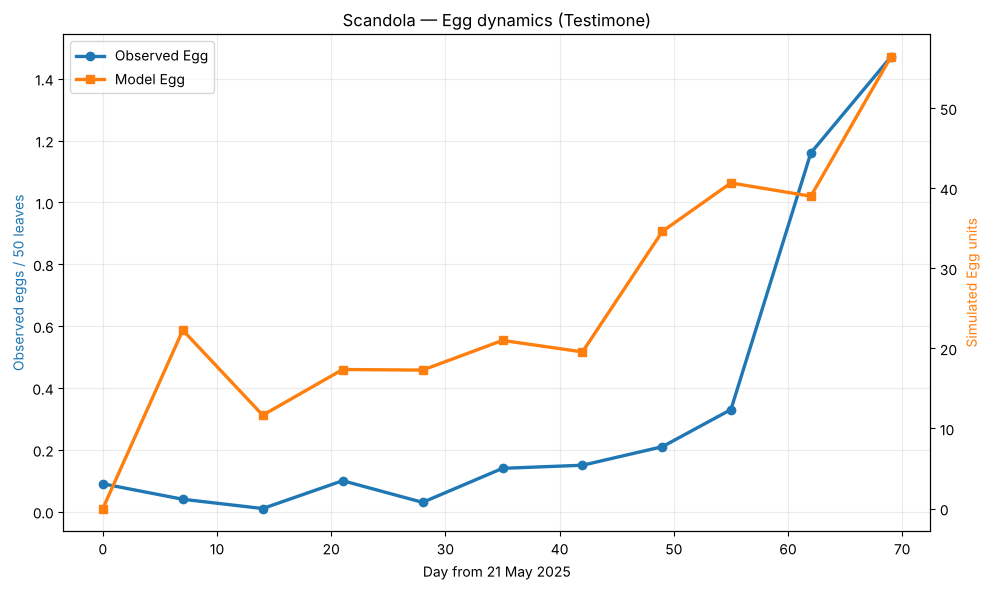

In [13]:
fig, ax1 = plt.subplots(figsize=(10,6))
ax2 = ax1.twinx()
ax1.plot(test_obs["Day"], test_obs["UOVA"], color="tab:blue", marker="o", linewidth=2.4, label="Observed Egg")
ax2.plot(test_obs["Day"], z.loc[obs_days,"Eggs"], color="tab:orange", marker="s", linewidth=2.4, label="Model Egg")
ax1.set_xlabel("Day from 21 May 2025")
ax1.set_ylabel("Observed eggs / 50 leaves", color="tab:blue")
ax2.set_ylabel("Simulated Egg units", color="tab:orange")
ax1.set_title("Scandola — Egg dynamics (Testimone)")
ax1.grid(alpha=.25)
h1,l1=ax1.get_legend_handles_labels(); h2,l2=ax2.get_legend_handles_labels()
ax1.legend(h1+h2,l1+l2,loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "01_EGG_TESTIMONE.png", dpi=220, bbox_inches="tight")
plt.show()

### Larva

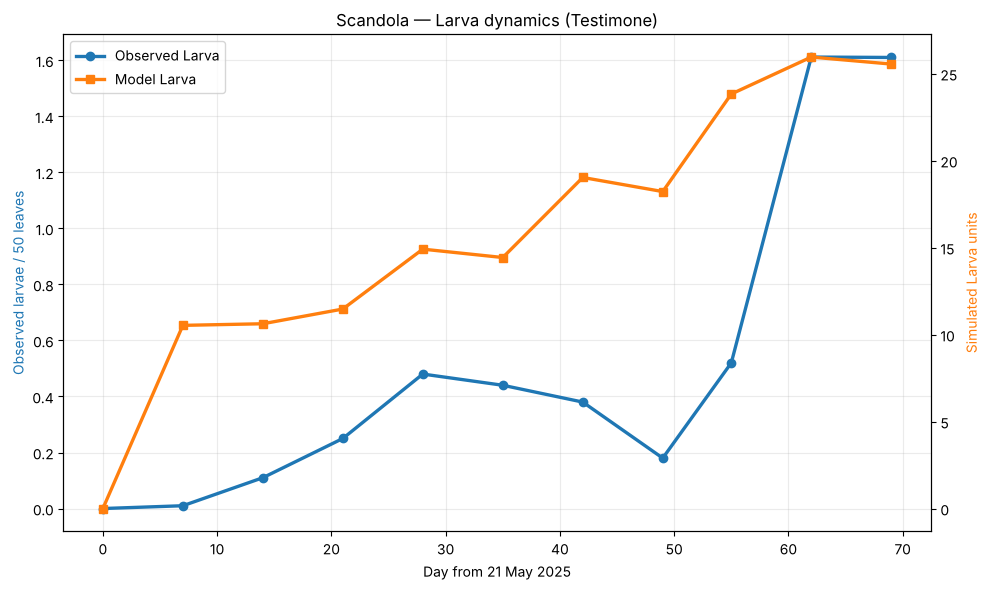

In [14]:
fig, ax1 = plt.subplots(figsize=(10,6))
ax2 = ax1.twinx()
ax1.plot(test_obs["Day"], test_obs["Larva_total"], color="tab:blue", marker="o", linewidth=2.4, label="Observed Larva")
ax2.plot(test_obs["Day"], z.loc[obs_days,"Larvae"], color="tab:orange", marker="s", linewidth=2.4, label="Model Larva")
ax1.set_xlabel("Day from 21 May 2025")
ax1.set_ylabel("Observed larvae / 50 leaves", color="tab:blue")
ax2.set_ylabel("Simulated Larva units", color="tab:orange")
ax1.set_title("Scandola — Larva dynamics (Testimone)")
ax1.grid(alpha=.25)
h1,l1=ax1.get_legend_handles_labels(); h2,l2=ax2.get_legend_handles_labels()
ax1.legend(h1+h2,l1+l2,loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "02_LARVA_TESTIMONE.png", dpi=220, bbox_inches="tight")
plt.show()

## 8. Crop response

In [15]:
no_tuta = run_simulation(TESTIMONE_PARAMS, forcing_mode="NT2", n_days=N_DAYS, with_tuta=False)
no_tuta.to_csv(OUT / "testimone_no_tuta_daily.csv", index=False)

impact = final_test[["Day","Larvae","LAI","Leaf_Consumption","Damage_LAI","Fruit_total"]].merge(
    no_tuta[["Day","LAI","Fruit_total"]], on="Day", suffixes=("_with_tuta","_no_tuta")
)
impact["LAI_loss"] = impact["LAI_no_tuta"] - impact["LAI_with_tuta"]
impact["Fruit_loss"] = impact["Fruit_total_no_tuta"] - impact["Fruit_total_with_tuta"]
impact.to_csv(OUT / "crop_impact_daily.csv", index=False)

summary = pd.DataFrame([{
    "Final_day": int(impact.iloc[-1]["Day"]),
    "Final_LAI_loss": float(impact.iloc[-1]["LAI_loss"]),
    "Final_fruit_loss": float(impact.iloc[-1]["Fruit_loss"]),
    "Final_fruit_loss_percent": float(100*impact.iloc[-1]["Fruit_loss"] / impact.iloc[-1]["Fruit_total_no_tuta"]),
}])
display(summary.round(4))
summary.to_csv(OUT / "crop_impact_summary.csv", index=False)

,Final_day,Final_LAI_loss,Final_fruit_loss,Final_fruit_loss_percent
0,76,0.0543,12.4706,1.3239


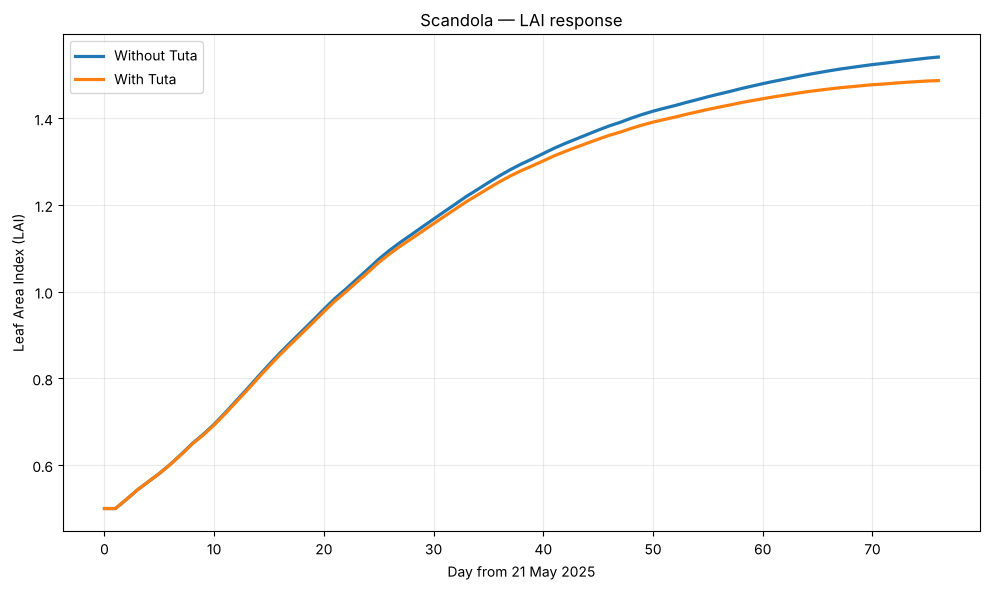

In [16]:
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(no_tuta["Day"], no_tuta["LAI"], linewidth=2.3, label="Without Tuta")
ax.plot(final_test["Day"], final_test["LAI"], linewidth=2.3, label="With Tuta")
ax.set_xlabel("Day from 21 May 2025")
ax.set_ylabel("Leaf Area Index (LAI)")
ax.set_title("Scandola — LAI response")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(OUT / "03_LAI_RESPONSE.png", dpi=220, bbox_inches="tight")
plt.show()

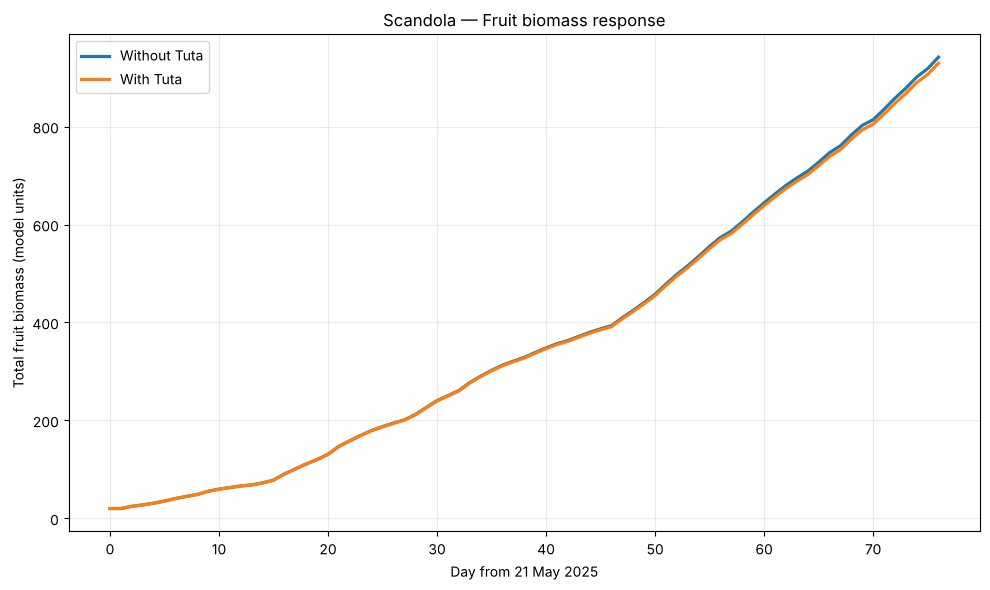

In [17]:
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(no_tuta["Day"], no_tuta["Fruit_total"], linewidth=2.3, label="Without Tuta")
ax.plot(final_test["Day"], final_test["Fruit_total"], linewidth=2.3, label="With Tuta")
ax.set_xlabel("Day from 21 May 2025")
ax.set_ylabel("Total fruit biomass (model units)")
ax.set_title("Scandola — Fruit biomass response")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(OUT / "04_FRUIT_RESPONSE.png", dpi=220, bbox_inches="tight")
plt.show()

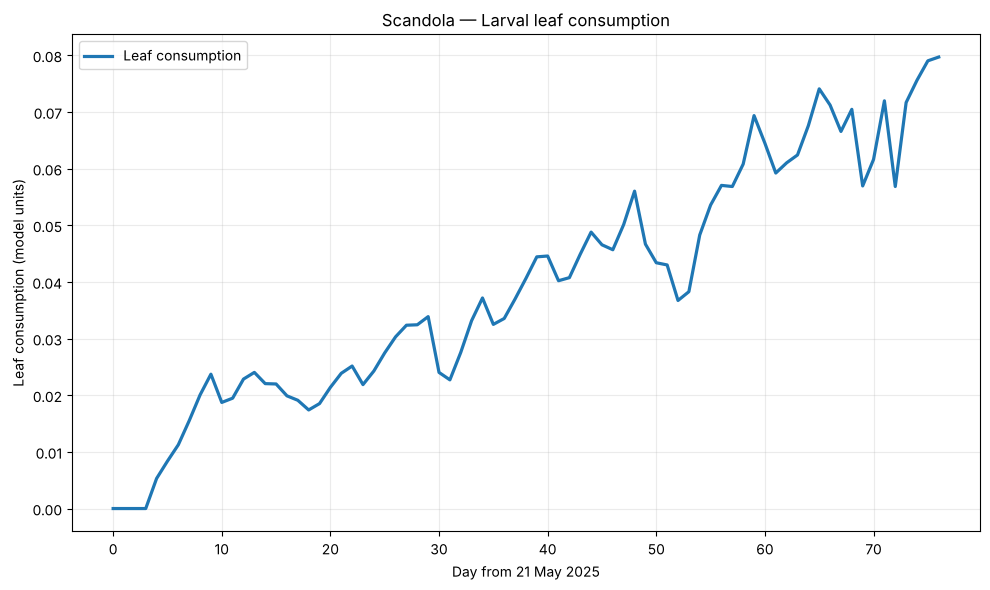

In [18]:
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(impact["Day"], impact["Leaf_Consumption"], linewidth=2.3, label="Leaf consumption")
ax.set_xlabel("Day from 21 May 2025")
ax.set_ylabel("Leaf consumption (model units)")
ax.set_title("Scandola — Larval leaf consumption")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(OUT / "05_LEAF_CONSUMPTION.png", dpi=220, bbox_inches="tight")
plt.show()

## 9. Adult trap comparison

Trap catches accumulate between inspections, so the simulated Adult state is integrated over each trapping interval before comparison.

The Adult series uses the Adult output of the **retained Testimone run** — the same configuration that produces the Egg and Larva results above. No separate adult parameterisation is introduced.

Two traps were deployed, one per tunnel. Testimone replicate 1 is in tunnel 1 together with the integrated-strategy area, so the tunnel-1 trap series is the one used here.

In [19]:
from scipy.stats import spearmanr

AD = adult_obs["Day"].to_numpy(int)
AO = adult_obs[ADULT_TRAP_COLUMN].to_numpy(float)
AI = adult_interval_integrals(final_test, AD)   # retained Testimone run

pd.DataFrame({
    "Interval_end_day": AD[1:],
    "Observed_trap": AO[1:],
    "Simulated_adult_interval_exposure": AI,
}).to_csv(OUT / "adult_intervals.csv", index=False)

adult_metrics = pd.DataFrame([{
    "Trap_series": ADULT_TRAP_COLUMN,
    "Adult_interval_r": corr(AO[1:], AI),
    "Adult_interval_rho": float(spearmanr(AO[1:], AI)[0]),
    "Adult_direction": direction_score(AO[1:], AI),
    "Adult_direction_total": len(AI) - 1,
    "Observed_peak_interval_end_day": int(AD[1:][AO[1:].argmax()]),
    "Simulated_peak_interval_end_day": int(AD[1:][AI.argmax()]),
}])
display(adult_metrics.round(4))
adult_metrics.to_csv(OUT / "adult_metrics.csv", index=False)


,Trap_series,Adult_interval_r,Adult_interval_rho,Adult_direction,Adult_direction_total,Observed_peak_interval_end_day,Simulated_peak_interval_end_day
0,Strat. Int.,0.9983,0.8743,5,7,62,62


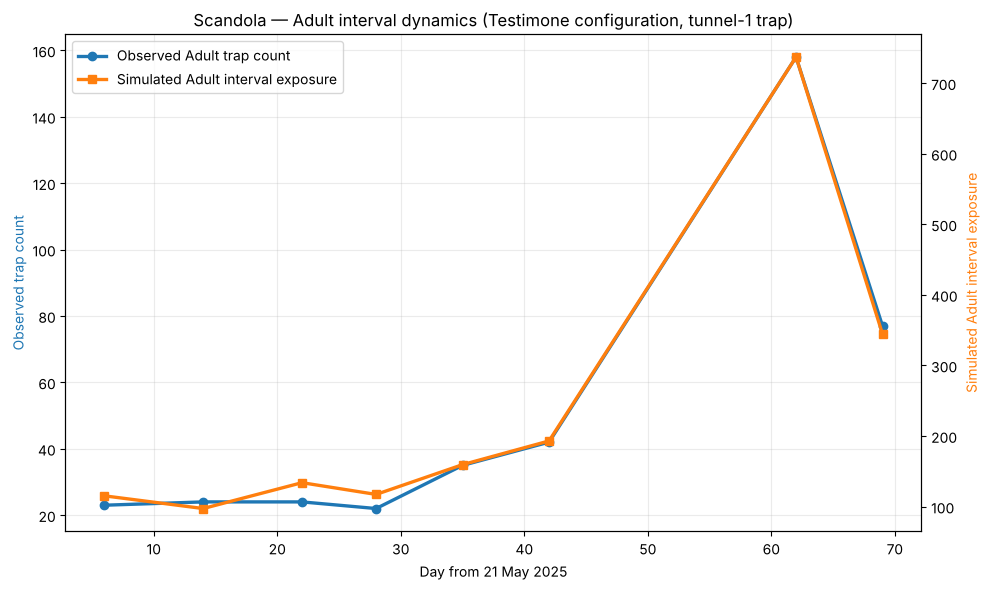

In [20]:
fig, ax1 = plt.subplots(figsize=(10,6))
ax2 = ax1.twinx()
ax1.plot(AD[1:], AO[1:], color="tab:blue", marker="o", linewidth=2.4, label="Observed Adult trap count")
ax2.plot(AD[1:], AI, color="tab:orange", marker="s", linewidth=2.4, label="Simulated Adult interval exposure")
ax1.set_xlabel("Day from 21 May 2025")
ax1.set_ylabel("Observed trap count", color="tab:blue")
ax2.set_ylabel("Simulated Adult interval exposure", color="tab:orange")
ax1.set_title("Scandola — Adult interval dynamics (Testimone configuration, tunnel-1 trap)")
ax1.grid(alpha=.25)
h1,l1=ax1.get_legend_handles_labels(); h2,l2=ax2.get_legend_handles_labels()
ax1.legend(h1+h2,l1+l2,loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "06_ADULT_TRAP_COMPARISON.png", dpi=220, bbox_inches="tight")
plt.show()

## 10. Output summary

In [21]:
print("Generated files:")
for p in sorted(OUT.iterdir()):
    print(" -", p.name)

Generated files:
 - 01_EGG_TESTIMONE.png
 - 02_LARVA_TESTIMONE.png
 - 03_LAI_RESPONSE.png
 - 04_FRUIT_RESPONSE.png
 - 05_LEAF_CONSUMPTION.png
 - 06_ADULT_TRAP_COMPARISON.png
 - adult_intervals.csv
 - adult_metrics.csv
 - crop_impact_daily.csv
 - crop_impact_summary.csv
 - engine_input_NT2_76d.csv
 - engine_input_T2_76d.csv
 - selected_parameters.csv
 - testimone_no_tuta_daily.csv
 - testimone_selected_daily.csv
